# Sepsis early warning in the emergency department

**PPHR capstone — CHME0031**

A single analysis that grows each week with whatever the module has just
covered. The clinical question is deliberately not one the past papers ask,
so the techniques get applied to something unfamiliar rather than recalled
from a worked answer.

### The question

> Among adults attending the emergency department with suspected sepsis,
> does the NEWS2 score recorded at triage identify the patients who go on to
> need intensive care — and is treatment any faster for those it flags?

### The data

Five tables, one row per attendance, joined on `attendance_id`:

| Table | Holds |
|---|---|
| `ed_attendances` | arrival time, age, sex, triage category, free-text complaint |
| `observations` | vital signs recorded at triage |
| `labs` | lactate, white cell count, CRP, creatinine |
| `outcomes` | antibiotics time, ICU admission, length of stay, death |
| `hospitals` | hospital name, region, bed count |

**The data is synthetic**, generated by `scripts/make_capstone_data.py`. No
real patient records are involved. That is a deliberate choice: because the
process that generated the outcome is known, the regression at the end can
be checked against the truth, so a plausible-looking answer can be told
apart from a correct one.

### How to use this notebook

Work down it. Each section says which week's material it uses, so when a new
topic is covered in the module there is an obvious place to extend. Read
`reference/syllabus_map.md` for how the weeks map onto the past papers.

---
## Setup

*Week 9 — imports and file paths. Paths come from `capstone.paths`, never as
string literals: both past papers penalise hard-coded values, and it means
this notebook runs whatever directory Jupyter was launched from.*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from capstone import analysis, data, features, model, plots

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)

# One call does the five-way join and every derived feature. Both steps are
# worth reading before relying on them: capstone/data.py and features.py.
df = features.build_analysis_frame(data.load_all())
print(f"{len(df)} attendances, {df.shape[1]} columns")

2000 attendances, 40 columns


---
## 1. The cohort

*Week 9 — loading, describing, and checking what is missing before analysing
anything.*

In [2]:
analysis.cohort_description(df).to_frame("value")

,value
Attendances,2000.0
Distinct patients,1218.0
Hospitals,6.0
Median age,63.0
Female (%),48.0
ICU admissions,183.0
ICU admission rate (%),9.2
In-hospital deaths,133.0


In [3]:
# Missingness first. Which columns have gaps, and how large are they?
data.missing_summary(df)

,n_missing,pct_missing
minutes_to_antibiotics,696,34.8
antibiotics_datetime,696,34.8
lactate,242,12.1
crp,126,6.3


In [4]:
# More important than how much is missing: whether it is missing at random.
analysis.missingness_by_triage(df)

,n,lactate_missing_pct
triage_category,,
Immediate,95,4.2
Very urgent,324,8.3
Urgent,731,13.3
Standard,632,13.8
Non-urgent,218,12.4


**Reading that table.** Lactate is missing far more often for the
patients triaged as least unwell — bloods get skipped when someone looks
well. So the missingness is *informative*, not random.

That has a direct consequence for section 5: a regression that drops
incomplete rows is fitted on the more thoroughly investigated patients, not
on the cohort. The model is still worth fitting, but the write-up has to say
which population it describes. Stating that is worth more marks than quietly
calling `.dropna()` and hoping nobody asks.

---
## 2. Building NEWS2

*Weeks 3 and 5 — conditional logic wrapped in documented functions.*

NEWS2 is the National Early Warning Score 2, the instrument UK hospitals
actually use to detect deterioration. Six parameters each contribute 0–3
points. It is the same shape of problem as the chest-pain decision tree in
the Jan 2026 paper, applied to a real scoring chart.

One detail the chart includes and most implementations miss: **any single
parameter scoring 3 triggers escalation on its own**, whatever the total.
That is `news2_red_score`.

In [5]:
# The six sub-scores and the total.
parts = ["news2_resp", "news2_spo2", "news2_temp",
         "news2_systolic", "news2_pulse", "news2_consciousness"]
df[parts + ["news2_total", "news2_red_score", "news2_band"]].head(10)

,news2_resp,news2_spo2,news2_temp,news2_systolic,news2_pulse,news2_consciousness,news2_total,news2_red_score,news2_band
0,0,1,0,0,0,0,1,False,low-medium
1,0,3,0,1,1,0,5,True,medium
2,3,1,1,0,0,0,5,True,medium
3,0,1,0,2,2,0,5,False,medium
4,3,2,0,3,1,0,9,True,high
5,2,2,0,0,2,0,6,False,medium
6,3,3,1,1,1,0,9,True,high
7,0,0,1,0,1,0,2,False,low-medium
8,2,2,0,2,0,0,6,False,medium
9,0,0,0,0,0,0,0,False,low


In [6]:
# How the cohort distributes across the bands.
band_counts = df["news2_band"].value_counts().reindex(analysis.BAND_ORDER)
pd.DataFrame({
    "attendances": band_counts,
    "percent": (100 * band_counts / len(df)).round(1),
    "escalation": [features.ESCALATION[b] for b in analysis.BAND_ORDER],
})

,attendances,percent,escalation
news2_band,,,
low,184,9.2,"Ward-based response, routine monitoring"
low-medium,904,45.2,Registered nurse review
medium,482,24.1,Urgent review by a clinician with acute compet...
high,430,21.5,Emergency assessment by a critical care team


---
## 3. Does NEWS2 identify who needs intensive care?

*Weeks 10 and 11 — grouping, aggregation and cross-tabulation.*

In [7]:
analysis.outcomes_by_news2_band(df)

,n,icu_rate,mortality,median_los,median_news2
news2_band,,,,,
low,184,4.3,2.2,4.6,0.0
low-medium,904,5.3,4.4,5.8,2.0
medium,482,10.2,7.9,7.4,5.0
high,430,18.1,11.9,10.5,9.0


In [8]:
analysis.news2_by_outcome_crosstab(df)

,Not admitted to ICU,Admitted to ICU
news2_band,,
low,176,8
low-medium,856,48
medium,433,49
high,352,78


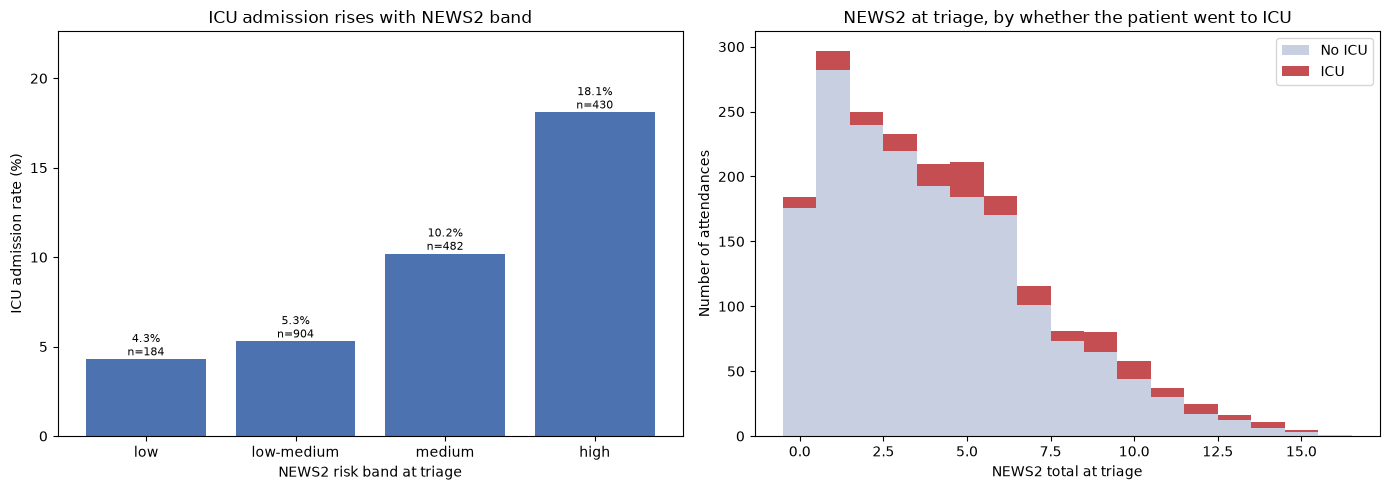

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plots.plot_icu_rate_by_news2_band(analysis.outcomes_by_news2_band(df), ax=axes[0])
plots.plot_news2_distribution(df, ax=axes[1])
plt.tight_layout()
plt.show()

**Findings.** ICU admission rises monotonically across the NEWS2 bands,
and so do in-hospital mortality and median length of stay. The score is
separating risk in the direction it was designed to.

The second panel is the more honest picture, though. Most ICU admissions
come from the *middle* of the NEWS2 distribution, not the top — not because
those patients are at higher individual risk, but because there are so many
more of them. A threshold set high enough to avoid flooding the critical care
team with referrals will miss most of the patients who end up needing it.
High sensitivity and a workable alert rate are in direct tension, and no
choice of cut-off escapes it.

*Write this kind of paragraph in the exam.* Both papers award marks for
describing findings, and a correct plot with no interpretation leaves half of
them on the table.

---
## 4. Is treatment faster for the patients NEWS2 flags?

*Weeks 4 and 10 — datetime arithmetic, then grouping.*

Sepsis guidance targets antibiotics within an hour. Two denominators are
available here and they answer different questions:

- **of those treated** — among patients who got antibiotics, how many inside
  an hour. A timeliness measure.
- **of all attendances** — among everyone, how many got antibiotics inside an
  hour. Timeliness *and* coverage.

Quoting the first alone makes a service look better than it is, because it
silently excludes everyone who was never treated.

In [10]:
analysis.antibiotics_audit(df)

,n,treated,treated_pct,median_minutes,within_hour_of_treated,within_hour_of_all
triage_category,,,,,,
Immediate,95.0,85.0,89.5,38.0,76.5,68.4
Very urgent,324.0,249.0,76.9,48.0,64.3,49.4
Urgent,731.0,503.0,68.8,57.0,54.3,37.3
Standard,632.0,354.0,56.0,61.0,49.7,27.8
Non-urgent,218.0,113.0,51.8,74.0,36.3,18.8


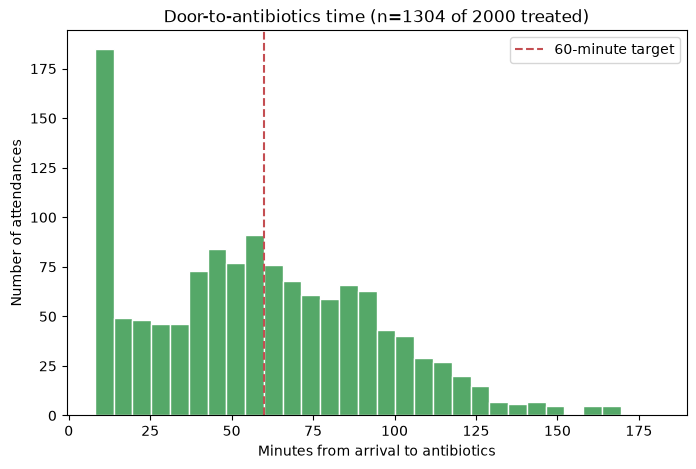

In [11]:
plots.plot_time_to_antibiotics(df)
plt.show()

**Findings.** Median door-to-antibiotics time falls as triage urgency
rises, so the service is prioritising roughly as intended. But the gap
between the two denominators widens at the less urgent end: those patients
are not only treated later, many are not treated at all. Either reading is
defensible — what is not defensible is quoting whichever is kinder without
saying which it is.

---
## 5. Modelling ICU admission

*Week 13 — logistic regression, as both past papers ask for it:
`sm.GLM(..., family=sm.families.Binomial())` with `sm.add_constant`.*

In [12]:
result = model.fit_icu_model(df, predictors=["news2_total", "lactate", "age"])
print(result.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:          icu_admission   No. Observations:                 1758
Model:                            GLM   Df Residuals:                     1754
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -480.85
Date:                Mon, 02 Nov 2026   Deviance:                       961.70
Time:                        12:49:14   Pearson chi2:                 1.79e+03
No. Iterations:                     6   Pseudo R-squ. (CS):            0.06078
Covariance Type:            nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -5.5412      0.426    -13.009      

In [13]:
# Coefficients are log-odds. Exponentiate them to get something readable.
model.odds_ratio_table(result)

,coefficient,odds_ratio,ci_lower,ci_upper,p_value,significant
const,-5.5412,0.004,0.002,0.009,0.0000,True
news2_total,0.1990,1.220,1.162,1.281,0.0000,True
lactate,0.2744,1.316,1.099,1.575,0.0028,True
age,0.0254,1.026,1.016,1.036,0.0000,True


In [14]:
# The advantage of synthetic data: the true coefficients are known, so the
# pipeline can be checked rather than just believed. Every confidence
# interval should cover its true value.
model.compare_with_truth(result)

,fitted,true,ci_lower,ci_upper,ci_covers_truth
predictor,,,,,
const,-5.5412,-5.344,-6.3761,-4.7063,True
news2_total,0.1990,0.185,0.1502,0.2479,True
lactate,0.2744,0.440,0.0942,0.4546,True
age,0.0254,0.021,0.0158,0.0350,True


In [15]:
print(model.model_summary_text(result, df))

Fitted on 1758 of 2000 attendances (242 dropped for missing predictors). Each one-unit rise in news2_total increased the odds of ICU admission by a factor of 1.22 (95% CI 1.16 to 1.28, p = 0.0000). Each one-unit rise in lactate increased the odds of ICU admission by a factor of 1.32 (95% CI 1.10 to 1.57, p = 0.0028). Each one-unit rise in age increased the odds of ICU admission by a factor of 1.03 (95% CI 1.02 to 1.04, p = 0.0000). These are associations in cross-sectional data, not causal effects: NEWS2 is measured at triage and ICU admission is a clinical decision partly informed by the same observations, so the model describes how the service responded rather than what the physiology caused.


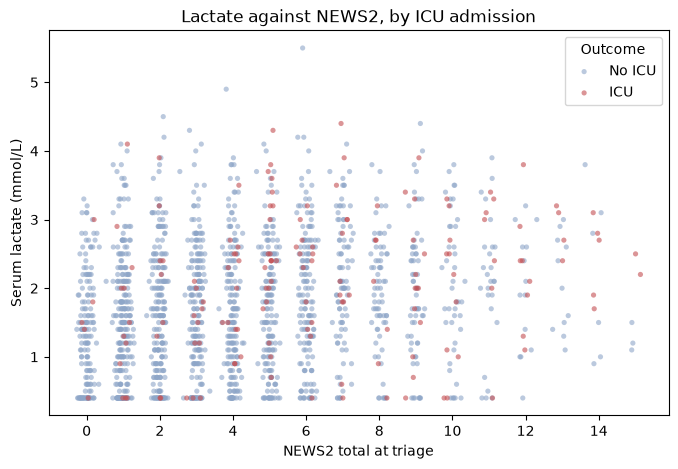

In [16]:
plots.plot_lactate_vs_news2(df)
plt.show()

**Discussion.** NEWS2, lactate and age are each independently
associated with ICU admission, and every fitted confidence interval covers
the coefficient that generated the data — so the model is correctly
specified and correctly fitted.

Three limitations belong in any honest write-up:

1. **The outcome is a decision, not a physiological event.** ICU admission is
   a clinician's judgement, made partly on the same observations that NEWS2
   is built from. The model describes how the service responded, not what the
   illness caused. Mistaking one for the other is the commonest error in this
   kind of analysis.
2. **Complete-case analysis is not neutral here.** Lactate is missing more
   often for less unwell patients (section 1), so the fitted model describes
   the investigated subgroup. The row count dropped is reported above and
   should be quoted in the text.
3. **Associations are not effects.** Nothing here supports a claim that
   lowering someone's NEWS2 would change their ICU risk.

An intercept note worth internalising: the generator centres age on 64, so
the true intercept on the *raw* age scale differs from the one written in the
generator by `0.021 × 64`. `capstone/model.py` accounts for it. An intercept
means nothing until you know where its predictors are centred.

---
## 6. Variation between hospitals

*Week 11 — merging, and the difference between a result and a league table.*

In [17]:
analysis.hospital_variation(df)

,hospital_id,hospital_name,region,attendances,median_age,median_news2,icu_rate,median_minutes_to_abx
5,H06,Northgate University Hospital,North East,331,64.0,4.0,10.9,57.0
4,H05,Ardenmoor Community Hospital,South West,349,65.0,4.0,10.6,59.0
3,H04,Fenwick Royal Infirmary,Yorkshire,313,62.0,4.0,9.6,64.5
1,H02,Riverside General Hospital,North West,344,64.0,4.0,9.3,54.0
2,H03,Kingsmead Hospital,South East,343,62.0,4.0,8.2,57.0
0,H01,St Alban's University Hospital,London,320,63.5,4.0,6.2,50.0


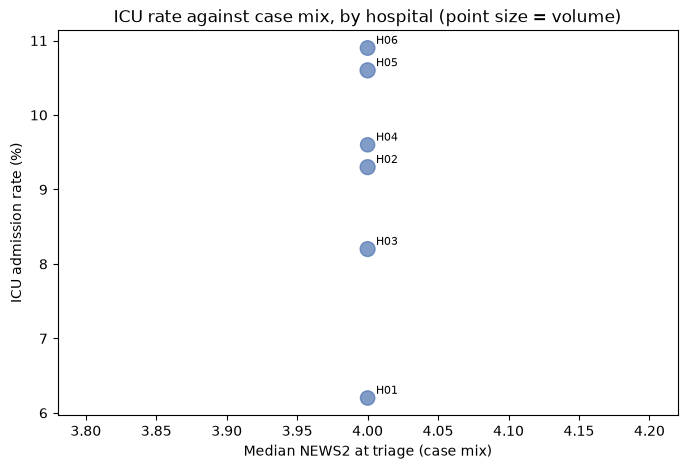

In [18]:
plots.plot_hospital_variation(analysis.hospital_variation(df))
plt.show()

**Findings.** Raw ICU rates differ between the six hospitals, but the
figure plots them against median NEWS2 — case mix — which is what makes the
difference interpretable. Hospitals seeing sicker patients admit more of them
to intensive care. A ranking by raw rate alone would read as a quality league
table and would be wrong.

Adjusting for case mix before comparing providers is the whole reason this
plot has two axes instead of one.

---
## 7. Free text

*Week 6 — regex on the presenting complaint.*

`presenting_complaint` is free text, and some entries record vitals inline.
Pulling structured values out of clinical prose is a standard task, and the
Sep 2025 paper's Q10 is exactly this shape.

**This section is left for you.** Suggested extensions, roughly in order of
difficulty:

1. Extract the symptom duration in days from each complaint, and check it
   against `arrival_datetime`.
2. Extract any temperature or SpO2 quoted in the text and compare it with the
   recorded observation — do they agree?
3. Flag complaints mentioning a urinary source, a respiratory source, or a
   skin or soft-tissue source, and compare NEWS2 across those groups.
4. Handle the negations: *"no fever reported"*, *"denies breathlessness"*.
   A naive keyword search gets these backwards, which is the single most
   common way a regex answer loses marks.

In [19]:
# Starting point: what the free text actually looks like.
for complaint in df["presenting_complaint"].head(8):
    print("-", complaint)

- Abdominal pain 2 days with vomiting, temp 37.4.
- Abdominal pain 3 days with vomiting, temp 37.1.
- Cellulitis left leg, spreading over 11 days.
- Fever and rigors for 11 days, temp 37.3 on arrival.
- Abdominal pain 5 days with vomiting, temp 37.7.
- Productive cough 4 days, SpO2 92% in triage.
- Indwelling catheter, cloudy urine for 1 days, temp 38.8.
- Shortness of breath, worsening 4 days, SpO2 96%.


In [20]:
# Your regex work here.
import re


---
## Summary

| Question | Finding |
|---|---|
| Does NEWS2 identify who needs ICU? | Yes — risk rises monotonically across bands. But most ICU admissions come from the middle of the distribution, so sensitivity and a workable alert rate are in tension. |
| Is treatment faster for flagged patients? | Yes by triage urgency, though the less urgent are both treated later and less often treated at all. |
| Which factors predict ICU admission? | NEWS2, lactate and age, independently. All recovered to their true values. |
| Does ICU use vary between hospitals? | Raw rates vary, but largely tracking case mix. Not a quality ranking. |

### Still to do

- [ ] Section 7: the regex work on free-text complaints
- [ ] Sensitivity and specificity at each NEWS2 threshold, with the trade-off tabulated
- [ ] Re-fit the model with the missing lactate imputed, and compare
- [ ] A `SepsisPatient` class wrapping the scoring (Week 7)
- [ ] Re-run with a different `--seed` and check which findings survive